# RNA – Projeto Prático 2.1: Aprendizado Supervisionado no Neurônio Perceptron
Equipe com identificador **0** (arquivos `data020262.txt`, semente = 0).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from neuron import PerceptronNeuron

ID_EQUIPE = 0

def carregar(caminho):
    d = np.load(caminho, allow_pickle=True).reshape(-1, 3)
    return d[:, :2], d[:, 2].astype(int)

## Parte I – Problema linearmente separável (`dataAll20262.txt`)
Ativação degrau (ϑ = 0), η = 0,1, pesos ~ U(−0,5; 0,5), treino até a convergência.

Exemplos: 1000
Pesos iniciais: [-0.35774965 -0.28083928  0.2044515 ]
Pesos finais:   [  -0.45774965   86.18731322 -425.75442383]
Total de ajustes: 65 | Épocas: 4


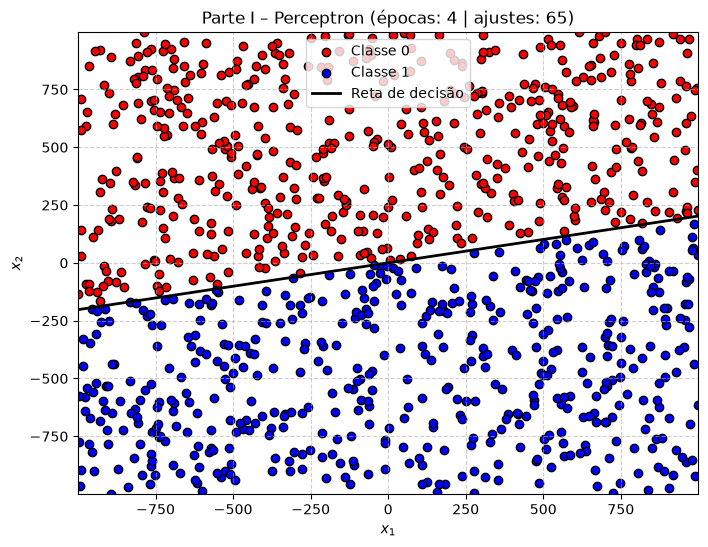

In [2]:
X, y = carregar("dados/dataAll20262.txt")
print("Exemplos:", X.shape[0])
p1 = PerceptronNeuron(learning_rate=0.1, limiar=0.0, weight_range=(-0.5, 0.5))
p1.train(X, y)
p1.plot_decision_boundary(X, y, title=f"Parte I – Perceptron (épocas: {p1.epochs} | ajustes: {p1.total_adjustments})")

## Parte II – Experimentação (`data{ID}20262.txt`)
6 configurações (η × intervalo dos pesos), 10 repetições cada.

In [3]:
X2, y2 = carregar(f"dados/data{ID_EQUIPE}20262.txt")
etas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
N_REP = 10
# Nos dados desta equipe a convergência exige centenas de milhares de épocas (margem pequena).
MAX_EPOCAS = None  # treina até a convergência (rápido graças ao kernel Numba em neuron.py)
rng = np.random.default_rng(ID_EQUIPE)

tabela = PrettyTable(["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes (média ± dp)", "Min Épocas", "Max Épocas", "Convergiram"])
resultados = {}
for eta in etas:
    for inter in intervalos:
        ajustes, epocas, conv = [], [], []
        for _ in range(N_REP):
            n = PerceptronNeuron(learning_rate=eta, limiar=0.0, weight_range=inter)
            n.train(X2, y2, max_epochs=MAX_EPOCAS, rng=rng, verbose=False)
            ajustes.append(n.total_adjustments)
            epocas.append(n.epochs)
            conv.append(bool(np.all(n.predict(X2) == y2)))
        resultados[(eta, inter)] = (np.array(ajustes), np.array(epocas))
        tabela.add_row([f"η = {eta}", f"({inter[0]}, {inter[1]})",
                        f"{np.mean(ajustes):.2f} ± {np.std(ajustes):.2f}", min(epocas), max(epocas), f"{sum(conv)}/{N_REP}"])
print(tabela)

+---------------------+--------------------+---------------------------+------------+------------+-------------+
| Taxa de Aprendizado | Intervalo de Pesos | Qtde Ajustes (média ± dp) | Min Épocas | Max Épocas | Convergiram |
+---------------------+--------------------+---------------------------+------------+------------+-------------+
|       η = 0.4       |    (-100, 100)     |    2811795.30 ± 3427.83   |   239736   |   241613   |    10/10    |
|       η = 0.4       |    (-0.5, 0.5)     |    2810254.10 ± 3429.73   |   239581   |   241495   |    10/10    |
|       η = 0.1       |    (-100, 100)     |    2810399.60 ± 3880.85   |   239634   |   241630   |    10/10    |
|       η = 0.1       |    (-0.5, 0.5)     |    2809272.60 ± 2626.34   |   239656   |   240720   |    10/10    |
|       η = 0.01      |    (-100, 100)     |    2809059.70 ± 4934.06   |   239462   |   241214   |    10/10    |
|       η = 0.01      |    (-0.5, 0.5)     |    2810193.00 ± 2683.08   |   239762   |   240932  

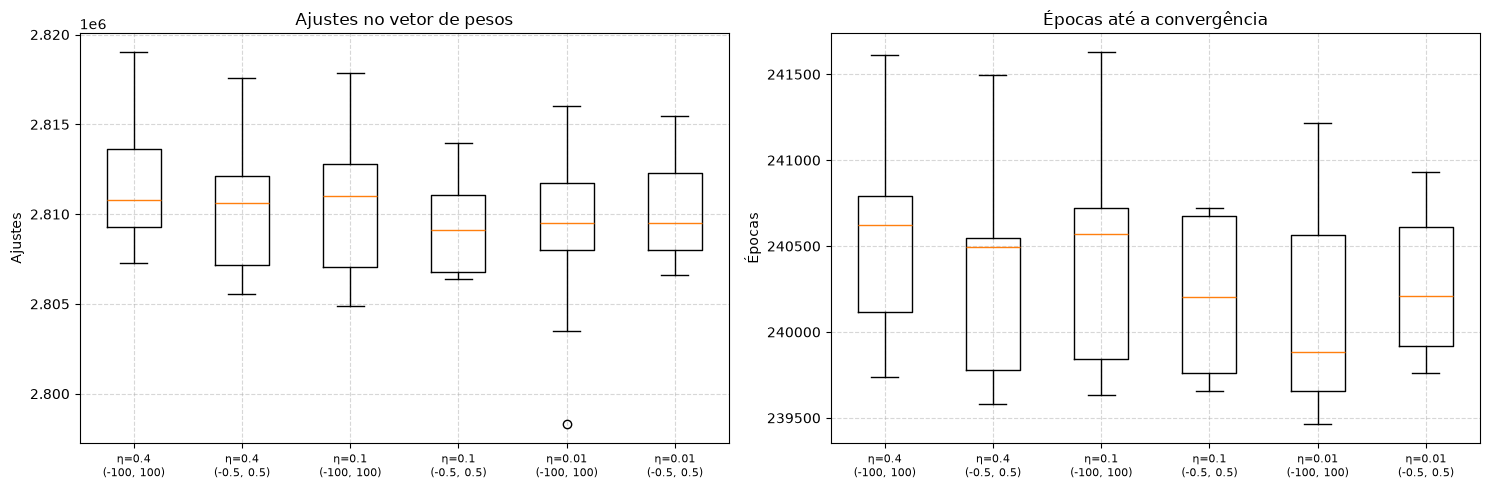

In [4]:
rotulos = [f"η={e}\n{i}" for (e, i) in resultados]
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].boxplot([r[0] for r in resultados.values()], tick_labels=rotulos)
axs[0].set_title("Ajustes no vetor de pesos"); axs[0].set_ylabel("Ajustes")
axs[1].boxplot([r[1] for r in resultados.values()], tick_labels=rotulos)
axs[1].set_title("Épocas até a convergência"); axs[1].set_ylabel("Épocas")
for a in axs: a.grid(True, linestyle="--", alpha=0.5); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### Análise
Nas 60 execuções (6 configurações × 10 repetições) todas convergiram, com cerca de 2,81 milhões de ajustes e entre 239 mil e 242 mil épocas. As médias e os desvios-padrão são praticamente idênticos entre as configurações e os boxplots se sobrepõem por completo.

**Não há evidência de uma configuração melhor ou pior: as seis são equivalentes** para estes dados. Explicações:
- A regra do Perceptron é homogênea: o degrau só depende do sinal de w·x, e cada ajuste soma η·e·x. Com η maior, o vetor w apenas cresce em escala; a fronteira de decisão é a mesma e o número de erros não muda.
- Os dados estão na escala de ±1000 e a margem entre as classes é pequena. Os pesos iniciais (mesmo em (−100, +100)) são desprezíveis diante da magnitude dos ajustes acumulados ao longo de milhões de atualizações, então o intervalo de inicialização também não afeta o resultado.
- O fator determinante é a geometria dos dados (margem pequena em relação ao raio da nuvem), que explica o número elevado de épocas em todas as configurações.

## Parte III – Validação Holdout em Problema Não-Linearmente Separável

Arquivo utilizado: `dados/dataHoldout20262.txt`. A equipe tem identificador **0**, portanto a semente utilizada na divisão aleatória é 0. O conjunto é dividido em 70% para treinamento e 30% para teste. O neurônio utiliza ativação degrau com ϑ = 0, η = 0,1, pesos iniciais em U(−0,5, +0,5) e treinamento por exatamente 100 épocas, embaralhando os exemplos de treinamento a cada época.

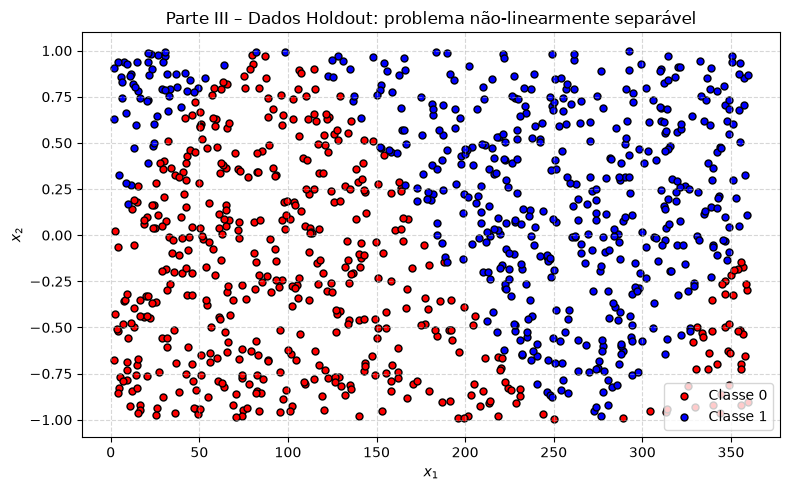

In [5]:
# Carregamento do conjunto Holdout
Xh, yh = carregar("dados/dataHoldout20262.txt")

# Gráfico inicial: as classes apresentam regiões de sobreposição,
# evidenciando que uma única reta não consegue separar perfeitamente os exemplos.
plt.figure(figsize=(8, 5))
plt.scatter(Xh[yh == 0, 0], Xh[yh == 0, 1], color="red", label="Classe 0", edgecolors="k", s=25)
plt.scatter(Xh[yh == 1, 0], Xh[yh == 1, 1], color="blue", label="Classe 1", edgecolors="k", s=25)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Parte III – Dados Holdout: problema não-linearmente separável")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Divisão Holdout 70/30

A divisão é realizada sem `train_test_split`, utilizando apenas NumPy, com semente igual ao identificador da equipe.

In [6]:
rng_split = np.random.default_rng(ID_EQUIPE)
indices = rng_split.permutation(len(Xh))
n_treino = int(0.70 * len(Xh))

indices_treino = indices[:n_treino]
indices_teste = indices[n_treino:]

X_treino, y_treino = Xh[indices_treino], yh[indices_treino]
X_teste, y_teste = Xh[indices_teste], yh[indices_teste]

print(f"Exemplos de treinamento: {len(X_treino)}")
print(f"Exemplos de teste: {len(X_teste)}")
print(f"Classes no treinamento: 0 = {np.sum(y_treino == 0)}, 1 = {np.sum(y_treino == 1)}")
print(f"Classes no teste: 0 = {np.sum(y_teste == 0)}, 1 = {np.sum(y_teste == 1)}")


Exemplos de treinamento: 700
Exemplos de teste: 300
Classes no treinamento: 0 = 348, 1 = 352
Classes no teste: 0 = 144, 1 = 156


In [7]:
# Treinamento do Perceptron por exatamente 100 épocas.
# Os exemplos são embaralhados a cada época (shuffle=True).
perceptron3 = PerceptronNeuron(
    learning_rate=0.1,
    limiar=0.0,
    weight_range=(-0.5, 0.5)
)

rng_treino = np.random.default_rng(ID_EQUIPE)
perceptron3.train(
    X_treino,
    y_treino,
    max_epochs=100,
    shuffle=True,
    rng=rng_treino,
    verbose=True
)


Pesos iniciais: [-0.23021329 -0.45902648 -0.48347236]
Pesos finais:   [656.76978671  -4.86825361 601.30642474]
Total de ajustes: 29510 | Épocas: 100


In [10]:
# Previsões para treinamento e teste
y_pred_treino = perceptron3.predict(X_treino)
y_pred_teste = perceptron3.predict(X_teste)

# 1. Matriz de confusão para o conjunto de teste
matriz_confusao = confusion_matrix(y_teste, y_pred_teste)
print("Matriz de confusão – conjunto de teste:")
print(matriz_confusao)

# 2 e 3. Métricas solicitadas para o conjunto de treinamento
acuracia_treino = accuracy_score(y_treino, y_pred_treino)*100
precisao_treino = precision_score(y_treino, y_pred_treino, zero_division=0)*100
revocacao_treino = recall_score(y_treino, y_pred_treino, zero_division=0)*100
fscore_treino = f1_score(y_treino, y_pred_treino, zero_division=0)*100

print("\nMétricas – conjunto de treinamento:")
print(f"Acurácia:   {acuracia_treino:.2f}%")
print(f"Precisão:   {precisao_treino:.2f}%")
print(f"Revocação:  {revocacao_treino:.2f}%")
print(f"F-Score:    {fscore_treino:.2f}%")

# Métricas do teste são apresentadas também para fundamentar a discussão final.
acuracia_teste = accuracy_score(y_teste, y_pred_teste)
precisao_teste = precision_score(y_teste, y_pred_teste, zero_division=0)
revocacao_teste = recall_score(y_teste, y_pred_teste, zero_division=0)
fscore_teste = f1_score(y_teste, y_pred_teste, zero_division=0)

print("\nMétricas – conjunto de teste:")
print(f"Acurácia:   {acuracia_teste:.2f}%")
print(f"Precisão:   {precisao_teste:.2f}%")
print(f"Revocação:  {revocacao_teste:.2f}%")
print(f"F-Score:    {fscore_teste:.2f}%")


Matriz de confusão – conjunto de teste:
[[144   0]
 [156   0]]

Métricas – conjunto de treinamento:
Acurácia:   49.71%
Precisão:   0.00%
Revocação:  0.00%
F-Score:    0.00%

Métricas – conjunto de teste:
Acurácia:   0.48%
Precisão:   0.00%
Revocação:  0.00%
F-Score:    0.00%


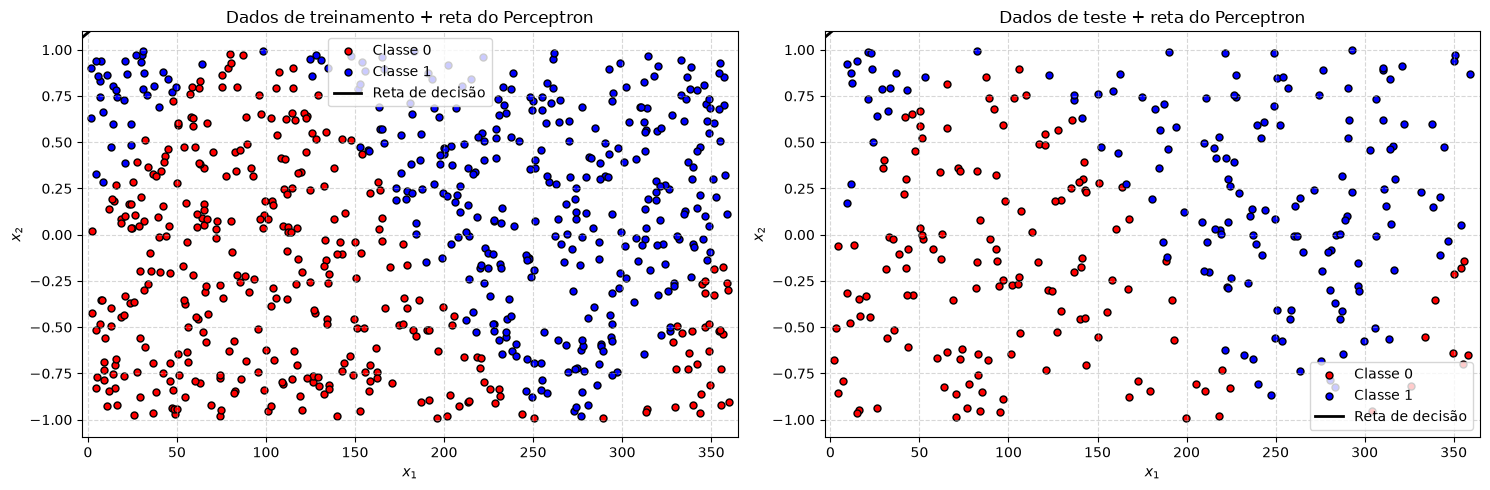

In [9]:
# Gráficos de treinamento e teste.
# A mesma reta aprendida pelo Perceptron é exibida nos dois gráficos.
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

def plot_holdout(ax, X, y, titulo):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], color="red", label="Classe 0", edgecolors="k", s=25)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color="blue", label="Classe 1", edgecolors="k", s=25)

    x_min, x_max = Xh[:, 0].min() - 5, Xh[:, 0].max() + 5
    y_min, y_max = Xh[:, 1].min() - 0.1, Xh[:, 1].max() + 0.1
    w0, w1, w2 = perceptron3.weights
    x_vals = np.array([x_min, x_max])

    if w2 != 0:
        y_vals = (w0 - w1 * x_vals) / w2
        ax.plot(x_vals, y_vals, color="black", linewidth=2, label="Reta de decisão")
    elif w1 != 0:
        ax.axvline(w0 / w1, color="black", linewidth=2, label="Reta de decisão")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(titulo)
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plot_holdout(axs[0], X_treino, y_treino, "Dados de treinamento + reta do Perceptron")
plot_holdout(axs[1], X_teste, y_teste, "Dados de teste + reta do Perceptron")
plt.tight_layout()
plt.show()


### Discussão dos resultados

O conjunto `dataHoldout20262.txt` não é linearmente separável, portanto o Perceptron não possui garantia de convergência para uma classificação perfeita. O treinamento foi limitado a 100 épocas, conforme solicitado, e os exemplos foram embaralhados em cada época.

Para esta execução da equipe 0, a solução obtida deve ser avaliada principalmente pela matriz de confusão e pelas métricas calculadas. A comparação entre acurácia, precisão, revocação e F-Score mostra o quanto a reta aprendida consegue representar um problema cuja fronteira real não é linear. Como o Perceptron produz apenas uma reta, erros de classificação são esperados nas regiões em que as classes se sobrepõem ou apresentam uma fronteira não linear.